# Vision — Segmentasi Instance (YOLOv8n-seg): masker per objek, bukan hanya kotak
**Kapan dipakai:** tiap objek butuh masker piksel sendiri → bisa dihitung, diukur luasnya,
dipisah dari objek lain yang bersentuhan.

**Langkah:** YOLOv8n-seg (zero-shot, COCO 80 kelas) → pasangkan masker prediksi dengan masker
asli (Hungarian pada IoU) → precision/recall pada IoU ≥ 0.5, rata-rata IoU pasangan, IoU
semantik (gabungan semua orang).

**Data demo:** Penn-Fudan (170 foto pejalan kaki). Masker asli di `PedMasks`, nilai piksel
1, 2, 3, … = orang ke-1, 2, 3. Bobot: `pretrained/yolov8n_seg/yolov8n-seg.pt`.

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from scipy.optimize import linear_sum_assignment
from ultralytics import YOLO

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/vision/detection/PennFudanPed"   # GANTI
IMAGE_FOLDER = f"{DATA_FOLDER}/PNGImages"
MASK_FOLDER = f"{DATA_FOLDER}/PedMasks"    # hanya ada di data latihan
IMAGE_PATTERN = "*.png"
MASK_SUFFIX = "_mask.png"                  # FudanPed00001.png → FudanPed00001_mask.png
WEIGHTS = "../../pretrained/yolov8n_seg/yolov8n-seg.pt"

COCO_CLASSES = [0]   # 0 = person di COCO
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = 0

## Baca data

jumlah gambar: 170
nilai piksel masker contoh: [0 1 2]


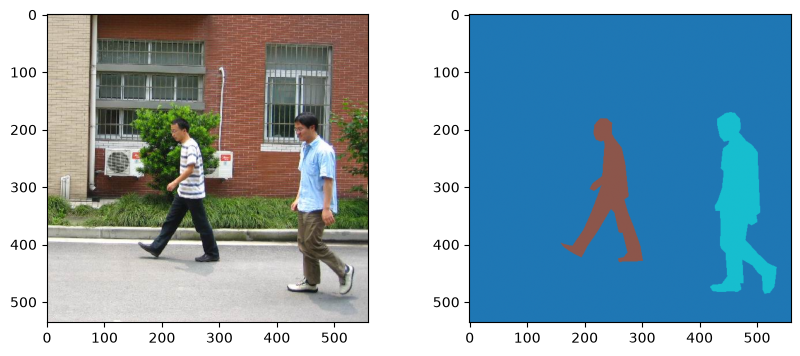

In [3]:
image_paths = sorted(glob.glob(f"{IMAGE_FOLDER}/{IMAGE_PATTERN}"))
print("jumlah gambar:", len(image_paths))


def mask_path(image_path):
    name = os.path.splitext(os.path.basename(image_path))[0]
    return f"{MASK_FOLDER}/{name}{MASK_SUFFIX}"


first_mask = np.array(Image.open(mask_path(image_paths[0])))
print("nilai piksel masker contoh:", np.unique(first_mask))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(Image.open(image_paths[0]))
axes[1].imshow(first_mask, cmap="tab10")
plt.show()

## Model + prediksi semua gambar
Pilih SATU ambang keyakinan: hapus `#` di baris yang ingin dipakai.

In [4]:
model = YOLO(WEIGHTS)
MIN_CONFIDENCE = 0.25
# MIN_CONFIDENCE = 0.5      # hanya objek yang jelas
IMAGE_SIZE = 640
# IMAGE_SIZE = 960          # objek kecil/jauh

results = []
for image_path in image_paths:
    image_results = model.predict(image_path, classes=COCO_CLASSES, retina_masks=True,
                                  conf=MIN_CONFIDENCE, imgsz=IMAGE_SIZE, device=DEVICE,
                                  verbose=False)
    results.append(image_results[0])

WARNING NMS time limit 2.050s exceeded


## Evaluasi: pasangkan masker prediksi dengan masker asli
`iou_matrix`: IoU tiap pasangan (masker prediksi, masker asli). Hungarian
(`linear_sum_assignment`) memilih pasangan satu-satu dengan total IoU terbesar.

In [5]:
def iou_matrix(pred_masks, true_masks):
    pred_flat = pred_masks.reshape(len(pred_masks), -1).astype(np.float32)
    true_flat = true_masks.reshape(len(true_masks), -1).astype(np.float32)
    intersection = pred_flat @ true_flat.T
    union = pred_flat.sum(1)[:, None] + true_flat.sum(1)[None, :] - intersection
    return intersection / np.maximum(union, 1)


pair_ious = []
pred_total = 0
true_total = 0
semantic_ious = []
for image_path, image_result in zip(image_paths, results):
    label_image = np.array(Image.open(mask_path(image_path)))
    true_masks = []
    for person_number in np.unique(label_image)[1:]:      # 0 = latar
        true_masks.append(label_image == person_number)
    true_masks = np.stack(true_masks)
    pred_masks = np.zeros((0,) + label_image.shape, dtype=bool)
    if image_result.masks is not None:
        pred_masks = image_result.masks.data.cpu().numpy() > 0.5
    ious = iou_matrix(pred_masks, true_masks)
    pred_rows, true_rows = linear_sum_assignment(-ious)
    pair_ious.extend(ious[pred_rows, true_rows])
    pred_total += len(pred_masks)
    true_total += len(true_masks)
    pred_any = pred_masks.any(axis=0)
    true_any = true_masks.any(axis=0)
    semantic_ious.append((pred_any & true_any).sum() / (pred_any | true_any).sum())

Precision rendah di sini wajar: Penn-Fudan tidak memberi masker untuk orang kecil / terpotong
di latar belakang, padahal model menemukannya. Naikkan `MIN_CONFIDENCE` bila soal hanya
menghitung objek jelas.

precision@0.5: 0.6158 | recall@0.5: 0.9929
rata-rata IoU pasangan: 0.822 | IoU semantik: 0.7904


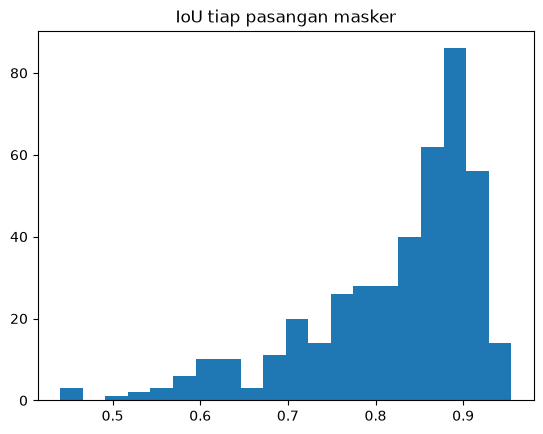

In [6]:
pair_ious = np.array(pair_ious)
correct = (pair_ious >= 0.5).sum()
print("precision@0.5:", round(correct / pred_total, 4), "| recall@0.5:",
      round(correct / true_total, 4))
print("rata-rata IoU pasangan:", round(pair_ious.mean(), 4), "| IoU semantik:",
      round(np.mean(semantic_ious), 4))
plt.hist(pair_ious, bins=20)
plt.title("IoU tiap pasangan masker")
plt.show()

## Contoh hasil (tiap orang satu warna)

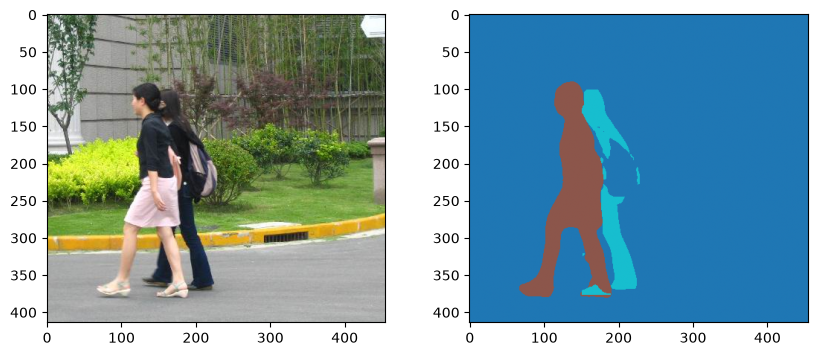

In [7]:
layers = results[1].masks.data.cpu().numpy()
person_numbers = np.arange(1, len(layers) + 1)[:, None, None]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(Image.open(image_paths[1]))
axes[1].imshow((layers * person_numbers).max(axis=0), cmap="tab10")
plt.show()

## Hasil per gambar: jumlah orang dan persen luas piksel orang

In [8]:
file_names = []
person_counts = []
person_percents = []
for image_path, image_result in zip(image_paths, results):
    file_names.append(os.path.basename(image_path))
    if image_result.masks is None:
        person_counts.append(0)
        person_percents.append(0)
        continue
    masks = image_result.masks.data.cpu().numpy() > 0.5
    person_counts.append(len(masks))
    person_percents.append(masks.any(axis=0).mean() * 100)

result = pd.DataFrame()
result["file"] = file_names
result["jumlah_orang"] = person_counts
result["persen_piksel_orang"] = person_percents
result.to_csv("hasil.csv", index=False)
result.head()

,file,jumlah_orang,persen_piksel_orang
0,FudanPed00001.png,2,10.610632
1,FudanPed00002.png,2,10.754897
2,FudanPed00003.png,1,8.818465
3,FudanPed00004.png,3,12.168918
4,FudanPed00005.png,3,14.807359
